# ASCAD Trace Exploration

Exploratory notebook to:
1. Load ASCAD dataset
2. Inspect single trace with metadata
3. Visualize the trace with cryptographic information

In [1]:
import sys
from pathlib import Path
import importlib

sys.path.insert(0, str(Path('.').resolve()))

import ascad_loader
importlib.reload(ascad_loader)
from ascad_loader import ASCADLoader

In [2]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use('default')
%matplotlib inline

In [3]:
# Define paths to ASCAD data
ascad_data_dir = Path('../ATMEGA_AES_v1/ATM_AES_v1_fixed_key/ASCAD_data')
ascad_file = ascad_data_dir / 'ASCAD_databases' / 'ASCAD.h5'
ascad_desync50 = ascad_data_dir / 'ASCAD_databases' / 'ASCAD_desync50.h5'

print(f'ASCAD data directory: {ascad_data_dir}')
print(f'Main file exists: {ascad_file.exists()}')
print(f'Desync50 file exists: {ascad_desync50.exists()}')

if ascad_file.exists():
    print(f'\nASCAD file size: {ascad_file.stat().st_size / (1024**3):.2f} GB')
else:
    print(f'\nWarning: {ascad_file} not found. Please verify the path.')

ASCAD data directory: ../ATMEGA_AES_v1/ATM_AES_v1_fixed_key/ASCAD_data
Main file exists: True
Desync50 file exists: True

ASCAD file size: 0.04 GB


## 1. Load ASCAD Dataset

In [4]:
print('Loading ASCAD profiling dataset...')
loader = ASCADLoader(verbose=True)
traces, labels, metadata = loader.load_ascad_file(str(ascad_file), split='profiling')

print('\n=== Dataset Summary ===')
print(f'Traces shape: {traces.shape} (traces x samples)')
print(f'Labels shape: {labels.shape}')
print(f'Traces dtype: {traces.dtype}, range: [{traces.min():.2f}, {traces.max():.2f}]')
print(f'Unique classes: {len(np.unique(labels))}')
print(f'Class distribution: min={np.bincount(labels).min()}, max={np.bincount(labels).max()} traces per class')
print(f'\nMetadata keys: {list(metadata.keys())}')
if metadata:
    for key, val in metadata.items():
        if isinstance(val, np.ndarray):
            print(f'  {key}: shape={val.shape}, dtype={val.dtype}')

Loading ASCAD profiling dataset...
Loading ASCAD profiling set from ../ATMEGA_AES_v1/ATM_AES_v1_fixed_key/ASCAD_data/ASCAD_databases/ASCAD.h5
  Traces shape: (50000, 700), dtype: float32
  Labels shape: (50000,), unique classes: 256
  Metadata keys loaded: ['plaintext', 'ciphertext', 'key', 'masks', 'desync']

=== Dataset Summary ===
Traces shape: (50000, 700) (traces x samples)
Labels shape: (50000,)
Traces dtype: float32, range: [-66.00, 47.00]
Unique classes: 256
Class distribution: min=154, max=244 traces per class

Metadata keys: ['plaintext', 'ciphertext', 'key', 'masks', 'desync']
  plaintext: shape=(50000, 16), dtype=uint8
  ciphertext: shape=(50000, 16), dtype=uint8
  key: shape=(50000, 16), dtype=uint8
  masks: shape=(50000, 16), dtype=uint8
  desync: shape=(50000, 1), dtype=uint32


## 2. Inspect Single Trace & Metadata

In [5]:
trace_idx = 43
trace = traces[trace_idx]
label = labels[trace_idx]

print(f'=== Selected Trace {trace_idx} ===')
print(f'Label (Sbox output): {label}')
print(f'Trace shape: {trace.shape}')
print(f'Trace stats: min={trace.min():.4f}, max={trace.max():.4f}, mean={trace.mean():.4f}, std={trace.std():.4f}')
print(f'\nFirst 10 samples: {trace[:10]}')
print(f'Last 10 samples: {trace[-10:]}')

print(f'\n=== Metadata for Trace {trace_idx} ===')
if 'plaintext' in metadata:
    pt = metadata['plaintext'][trace_idx]
    print(f"Plaintext: {' '.join(f'{b:02x}' for b in pt)}")
if 'key' in metadata:
    k = metadata['key'][trace_idx]
    print(f"Key:       {' '.join(f'{b:02x}' for b in k)}")
if 'masks' in metadata:
    m = metadata['masks'][trace_idx]
    print(f"Masks:     {' '.join(f'{b:02x}' for b in m)}")
if 'desync' in metadata:
    ds = metadata['desync'][trace_idx]
    print(f'Desync:    {ds}')
elif 'desync_offset' in metadata:
    ds = metadata['desync_offset'][trace_idx]
    print(f'Desync offset: {ds}')

=== Selected Trace 43 ===
Label (Sbox output): 21
Trace shape: (700,)
Trace stats: min=-62.0000, max=41.0000, mean=-11.1271, std=26.0256

First 10 samples: [ 22.  21.  16.   8.   1.  -9. -17. -28. -38. -46.]
Last 10 samples: [-50. -45. -42. -37. -32. -24. -13.  -2.   7.  12.]

=== Metadata for Trace 43 ===
Plaintext: 15 0d cf f6 e9 c5 ff 3f 08 e5 9a 69 45 29 d4 25
Key:       4d fb e0 f2 72 21 fe 10 a7 8d 4a dc 8e 49 04 69
Masks:     3f 99 ef b4 57 14 27 db e7 ac 3e 7c 26 d1 4d d5
Desync:    [0]


## 3. Plot Trace with Metadata

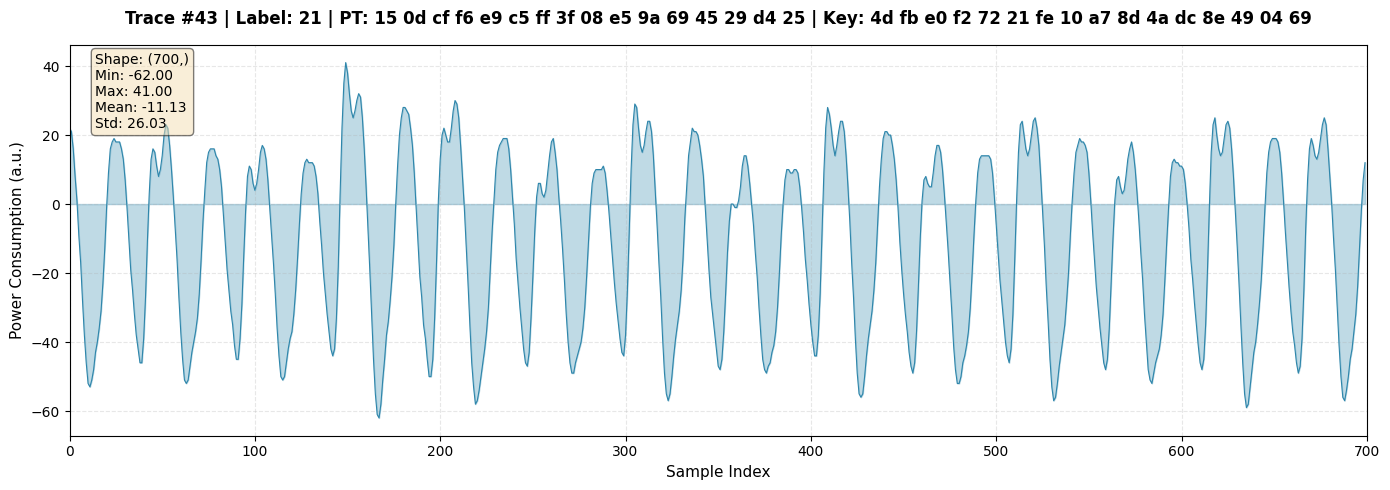


✓ Plotted trace 43 with label 21 and metadata


In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
samples = np.arange(len(trace))
ax.plot(samples, trace, linewidth=0.8, color='#2E86AB')
ax.fill_between(samples, trace, alpha=0.3, color='#2E86AB')

title_parts = [f'Trace #{trace_idx} | Label: {label}']
if 'plaintext' in metadata:
    pt_hex = ' '.join(f'{b:02x}' for b in metadata['plaintext'][trace_idx])
    title_parts.append(f'PT: {pt_hex}')
if 'key' in metadata:
    k_hex = ' '.join(f'{b:02x}' for b in metadata['key'][trace_idx])
    title_parts.append(f'Key: {k_hex}')

title = ' | '.join(title_parts)
ax.set_title(title, fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Sample Index', fontsize=11)
ax.set_ylabel('Power Consumption (a.u.)', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, len(trace))

stats_text = f'Shape: {trace.shape}\nMin: {trace.min():.2f}\nMax: {trace.max():.2f}\nMean: {trace.mean():.2f}\nStd: {trace.std():.2f}'
ax.text(0.02, 0.98, stats_text, transform=ax.transAxes, fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()
print(f'\n✓ Plotted trace {trace_idx} with label {label} and metadata')

## 4. Overlay 20 Traces from the Same Class

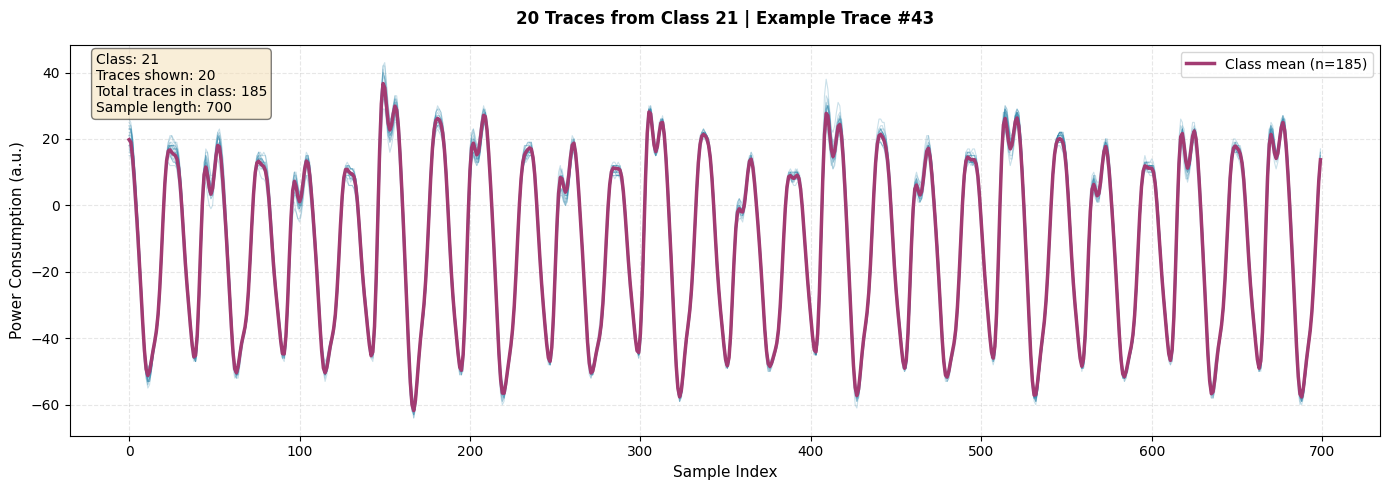


✓ Plotted 20 traces from class 21 on one figure


In [7]:
same_class_indices = np.where(labels == label)[0]
rng = np.random.default_rng(0)
selected_count = min(20, len(same_class_indices))
selected_indices = rng.choice(same_class_indices, size=selected_count, replace=False)

fig, ax = plt.subplots(figsize=(14, 5))
for idx in selected_indices:
    ax.plot(traces[idx], color='#2E86AB', alpha=0.25, linewidth=0.8)

class_mean = traces[same_class_indices].mean(axis=0)
ax.plot(class_mean, color='#A23B72', linewidth=2.5, label=f'Class mean (n={len(same_class_indices)})')
ax.set_title(f'{selected_count} Traces from Class {label} | Example Trace #{trace_idx}', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Sample Index', fontsize=11)
ax.set_ylabel('Power Consumption (a.u.)', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='best')

stats_text = f'Class: {label}\nTraces shown: {selected_count}\nTotal traces in class: {len(same_class_indices)}\nSample length: {trace.shape[0]}'
ax.text(0.02, 0.98, stats_text, transform=ax.transAxes, fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()
print(f'\n✓ Plotted {selected_count} traces from class {label} on one figure')

## 5. Compare 20 Traces from Two Different Classes (Same Axes)

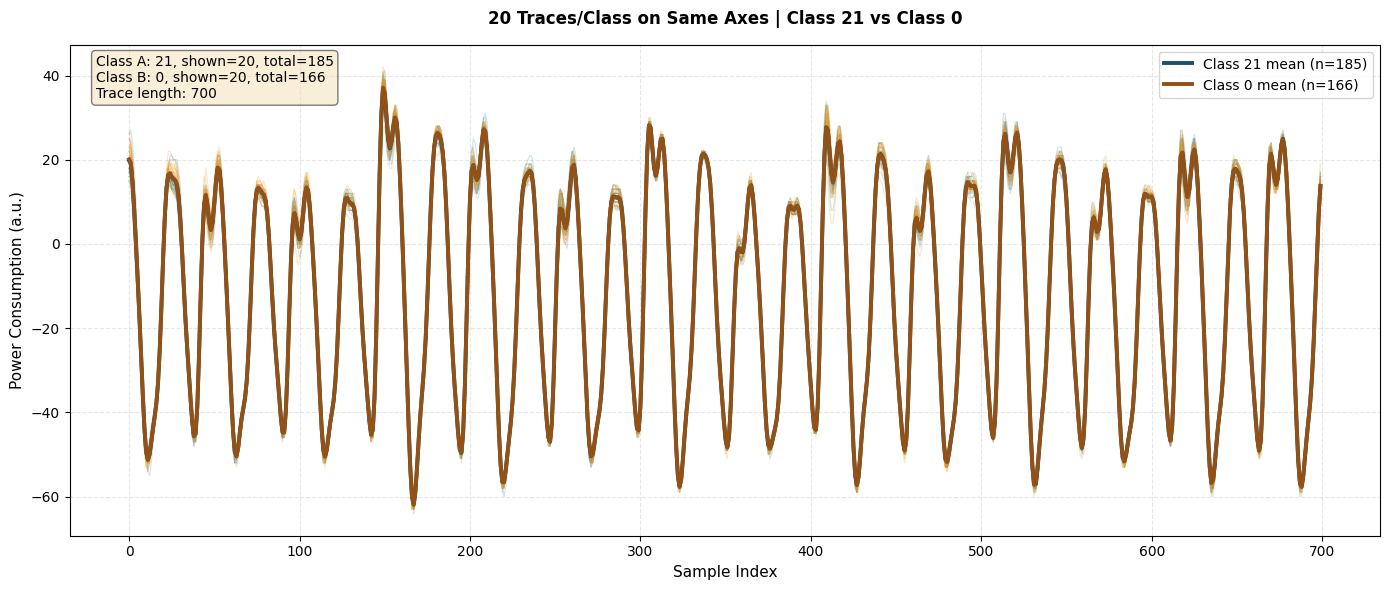


✓ Compared 20 traces from class 21 with 20 traces from class 0


In [8]:
class_a = int(label)
all_classes = np.unique(labels)
class_b_candidates = all_classes[all_classes != class_a]
class_b = int(class_b_candidates[0])

idx_a = np.where(labels == class_a)[0]
idx_b = np.where(labels == class_b)[0]

rng_cmp = np.random.default_rng(1)
count_a = min(20, len(idx_a))
count_b = min(20, len(idx_b))
sel_a = rng_cmp.choice(idx_a, size=count_a, replace=False)
sel_b = rng_cmp.choice(idx_b, size=count_b, replace=False)

fig, ax = plt.subplots(figsize=(14, 6))
for i in sel_a:
    ax.plot(traces[i], color='#2E86AB', alpha=0.22, linewidth=0.9)
for i in sel_b:
    ax.plot(traces[i], color='#F18F01', alpha=0.22, linewidth=0.9)

mean_a = traces[idx_a].mean(axis=0)
mean_b = traces[idx_b].mean(axis=0)
ax.plot(mean_a, color='#1B4F72', linewidth=2.8, label=f'Class {class_a} mean (n={len(idx_a)})')
ax.plot(mean_b, color='#935116', linewidth=2.8, label=f'Class {class_b} mean (n={len(idx_b)})')

ax.set_title(f'20 Traces/Class on Same Axes | Class {class_a} vs Class {class_b}', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Sample Index', fontsize=11)
ax.set_ylabel('Power Consumption (a.u.)', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='best')

cmp_text = f'Class A: {class_a}, shown={count_a}, total={len(idx_a)}\nClass B: {class_b}, shown={count_b}, total={len(idx_b)}\nTrace length: {traces.shape[1]}'
ax.text(0.02, 0.98, cmp_text, transform=ax.transAxes, fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()
print(f'\n✓ Compared {count_a} traces from class {class_a} with {count_b} traces from class {class_b}')

In [11]:
# print the metadata for the first 5 traces from class 0
class_0_indices = np.where(labels == 0)[0]
for i in range(min(5, len(class_0_indices))):
    idx = class_0_indices[i]
    print(f'\nTrace {idx}: Label={labels[idx]}')
    if 'plaintext' in metadata:
        pt = metadata['plaintext'][idx]
        print(f"  Plaintext: {' '.join(f'{b:02x}' for b in pt)}")
    if 'key' in metadata:
        k = metadata['key'][idx]
        print(f"  Key:       {' '.join(f'{b:02x}' for b in k)}")
    if 'masks' in metadata:
        m = metadata['masks'][idx]
        print(f"  Masks:     {' '.join(f'{b:02x}' for b in m)}")
    if 'desync' in metadata:
        ds = metadata['desync'][idx]
        print(f'  Desync:    {ds}')
    elif 'desync_offset' in metadata:
        ds = metadata['desync_offset'][idx]
        print(f'  Desync offset: {ds}')




Trace 237: Label=0
  Plaintext: a5 df b2 f2 ac b4 0c 39 f3 6b 96 5e 8e 51 5b b8
  Key:       4d fb e0 f2 72 21 fe 10 a7 8d 4a dc 8e 49 04 69
  Masks:     fa cb 53 33 c0 96 b4 9e ff 6b 15 f0 0b 00 10 92
  Desync:    [0]

Trace 252: Label=0
  Plaintext: 67 ed b2 a0 74 cc df f9 4a 22 e0 69 5c 1d a1 3b
  Key:       4d fb e0 f2 72 21 fe 10 a7 8d 4a dc 8e 49 04 69
  Masks:     07 bd b4 38 ba 44 6e db c1 ef 49 04 86 fb 68 a2
  Desync:    [0]

Trace 511: Label=0
  Plaintext: 22 00 b2 af 68 a7 09 8b 80 33 05 07 cf 60 78 76
  Key:       4d fb e0 f2 72 21 fe 10 a7 8d 4a dc 8e 49 04 69
  Masks:     89 48 71 51 e2 8b 73 0c c5 8b 0d 73 1f e4 4b c4
  Desync:    [0]

Trace 829: Label=0
  Plaintext: 4a 04 b2 2a c4 c6 f0 a0 26 41 ad 1f 02 fe 21 3e
  Key:       4d fb e0 f2 72 21 fe 10 a7 8d 4a dc 8e 49 04 69
  Masks:     de 85 a3 f5 d4 cb a0 61 74 c0 b0 29 e0 51 94 3c
  Desync:    [0]

Trace 877: Label=0
  Plaintext: a5 d2 b2 1a c4 1e a1 5e a8 7a 18 d8 51 94 eb c6
  Key:       4d fb e0 f2 72 21 fe 10 a7